# Sesión 5 · Reconocimiento: del clasificador clásico a la transferencia de aprendizaje
**Unidad 5. Reconocimiento de imágenes** · Procesamiento Digital de Imágenes · Maestría en Ciencia de Datos e Información · INFOTEC · 2027-1

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/egonzalez1989/pdi-mcdi/blob/main/sesiones/S5_Reconocimiento_clasico_y_profundo.ipynb)

**Objetivo de la sesión.** Entrenar y evaluar clasificadores sobre descriptores sin fuga de datos y compararlos con una red preentrenada.

**Clase síncrona:** jueves 15 de abril de 2027, de 18:00 a 20:00 hrs. · **Sesiones opcionales de la unidad** (18:00 a 19:00 hrs.): jueves 29 de abril (avance de la actividad 5A); jueves 13 de mayo (dudas de la actividad 5A); jueves 20 de mayo (retroalimentación de 5A y defensas orales).

**Agenda (120 min)**
1. Pipeline clásico: descriptores + k-NN, SVM y Random Forest (25 min)
2. Validación por grupos y fuga de datos (20 min)
3. Métricas y agrupamiento no supervisado (15 min)
4. Panorama: CNN y transferencia de aprendizaje con ResNet-18 (25 min)
5. Grad-CAM y análisis de errores (15 min)
6. Presentación de la actividad 5A (20 min)

**Cómo usar este cuaderno.** Ejecuta las celdas en orden (`Shift + Enter`). Las secciones marcadas con 🧪 son pausas para que experimentes cambiando parámetros; las marcadas con 💬 son preguntas para discutir en la sesión. Al final encontrarás la conexión con la actividad **5A**.

> **Recomendado:** en Colab activa la GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*). El cuaderno también funciona en CPU, solo más lento.

In [1]:
# Configuración del entorno. En Google Colab todas estas bibliotecas ya vienen instaladas.
import sys, platform
import numpy as np
import matplotlib.pyplot as plt
import cv2
import skimage
from skimage import data

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "image.cmap": "gray"})
np.random.seed(42)

def mostrar(imagenes, titulos=None, cols=None, cmap="gray", tam=3.2, ejes=False):
    """Muestra una lista de imágenes en una cuadrícula. Las imágenes a color deben estar en RGB."""
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    n = len(imagenes)
    cols = cols or min(n, 4)
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(tam * cols, tam * filas), squeeze=False)
    for i, ax in enumerate(axs.flat):
        if i < n:
            im = imagenes[i]
            ax.imshow(im, cmap=None if im.ndim == 3 else cmap)
            if titulos:
                ax.set_title(titulos[i])
        if not ejes or i >= n:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Python {platform.python_version()} | NumPy {np.__version__} | OpenCV {cv2.__version__} | scikit-image {skimage.__version__}")

import time
import pandas as pd
from scipy.stats import skew
from skimage import feature, color
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, GroupKFold, cross_val_score, cross_validate,
                                     GridSearchCV, train_test_split, GroupShuffleSplit)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score,
                             adjusted_rand_score)
from sklearn.cluster import KMeans
import torch, torch.nn as nn, torch.nn.functional as Fnn
import torchvision
from torchvision import models, transforms

torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| dispositivo:", DEVICE)

Python 3.12.15 | NumPy 2.5.4 | OpenCV 5.0.0 | scikit-image 0.26.0


PyTorch 2.15.0+cpu | torchvision 0.29.2+cpu | dispositivo: cpu


## 1. El problema y los datos
**Caso:** clasificar el material de una superficie a partir de parches de imagen (inspección de pisos, suelos o fachadas). Construimos un conjunto de datos de 5 clases con parches pequeños (32 × 32 píxeles), con variaciones de brillo, ruido, desenfoque y orientación, como ocurre con imágenes capturadas en campo.

Cada parche registra de qué **región de la imagen fuente** proviene (`grupo`). Esto será clave para evaluar sin fuga de datos: parches vecinos se parecen mucho entre sí, como fotos del mismo lote, paciente o cámara.

Imágenes: (500, 32, 32) | clases: [100 100 100 100 100] | grupos: 20


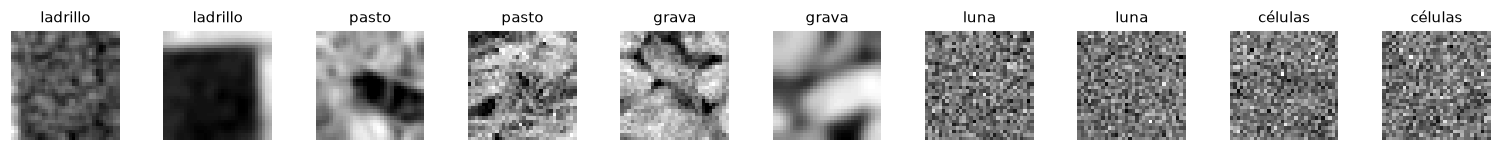

In [2]:
fuentes = {"ladrillo": data.brick(), "pasto": data.grass(), "grava": data.gravel(),
           "luna": cv2.resize(data.moon(), (512, 512)), "células": cv2.resize(data.cell(), (512, 512))}
P, N_POR_CLASE = 32, 100
rng = np.random.default_rng(0)
X_img, y, grupos = [], [], []
for c, (nombre, im) in enumerate(fuentes.items()):
    h, w = im.shape
    for _ in range(N_POR_CLASE):
        yy_, xx_ = rng.integers(0, h - P), rng.integers(0, w - P)
        p = im[yy_:yy_ + P, xx_:xx_ + P].astype(np.float32)
        p = np.rot90(p, rng.integers(4)).copy()                                              # orientación arbitraria
        p = p * rng.uniform(0.6, 1.4) + rng.uniform(-30, 30) + rng.normal(0, 12, p.shape)   # variación de captura
        if rng.random() < 0.5:
            p = cv2.GaussianBlur(p, (0, 0), rng.uniform(0.5, 2.0))                          # desenfoque frecuente
        X_img.append(np.clip(p, 0, 255).astype(np.uint8))
        y.append(c)
        grupos.append(c * 4 + (yy_ >= h // 2) * 2 + (xx_ >= w // 2))   # cuadrante de la imagen fuente
X_img, y, grupos = np.array(X_img), np.array(y), np.array(grupos)
NOMBRES = list(fuentes.keys())
print("Imágenes:", X_img.shape, "| clases:", np.bincount(y), "| grupos:", len(np.unique(grupos)))
idx = [k * N_POR_CLASE + j for k in range(5) for j in range(2)]
mostrar([X_img[i] for i in idx], [NOMBRES[y[i]] for i in idx], cols=10, tam=1.4)

## 2. Enfoque clásico: descriptores + clasificador
Reutilizamos los descriptores de la Unidad 4 (GLCM + LBP + estadísticos) y los metemos en un **`Pipeline`**: la estandarización se ajusta *dentro* de cada partición de entrenamiento, lo que evita una fuente común de fuga de datos.

In [3]:
def descriptor(p):
    q = (p // 8).astype(np.uint8)
    g = feature.graycomatrix(q, [1, 3], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=32, symmetric=True, normed=True)
    v = [feature.graycoprops(g, pr).mean(axis=1) for pr in ["contrast", "homogeneity", "energy", "correlation"]]
    lbp = feature.local_binary_pattern(p, 8, 1, "uniform")
    h, _ = np.histogram(lbp, bins=np.arange(11), density=True)
    return np.concatenate(v + [h, [p.std(), skew(p.ravel())]])   # sin la media: no queremos depender del brillo

t0 = time.time()
X_feat = np.array([descriptor(p) for p in X_img])
print(f"Matriz de diseño: {X_feat.shape} en {time.time()-t0:.1f}s")

Matriz de diseño: (500, 20) en 2.0s


### Validación: la fuga de datos que infla los resultados
Comparamos **validación cruzada estratificada aleatoria** contra **validación por grupos** (`GroupKFold`): en la segunda, todos los parches de un mismo cuadrante quedan en el mismo lado de la partición. Este es el escenario realista: el modelo verá imágenes de *nuevos* lotes.

In [4]:
modelos = {
    "k-NN (k=5)": KNeighborsClassifier(5),
    "SVM RBF": SVC(C=10, gamma="scale"),
    "Random Forest": RandomForestClassifier(300, random_state=0),
}
filas = []
for nombre, clf in modelos.items():
    pipe = Pipeline([("escala", StandardScaler()), ("clf", clf)])
    aleatoria = cross_val_score(pipe, X_feat, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="f1_macro")
    por_grupo = cross_val_score(pipe, X_feat, y, groups=grupos, cv=GroupKFold(4), scoring="f1_macro")
    filas.append((nombre, aleatoria.mean(), aleatoria.std(), por_grupo.mean(), por_grupo.std()))
res = pd.DataFrame(filas, columns=["Modelo", "F1 CV aleatoria", "±", "F1 CV por grupos", "± "]).round(3)
display(res)

,Modelo,F1 CV aleatoria,±,F1 CV por grupos,±
0,k-NN (k=5),0.772,0.029,0.621,0.077
1,SVM RBF,0.838,0.022,0.649,0.092
2,Random Forest,0.808,0.043,0.670,0.087


💬 **Discusión.** ¿Cuál de las dos cifras reportarías a tu cliente? La diferencia es la *estimación optimista* que produce la fuga de datos (Kapoor y Narayanan, 2023).

### Partición final y ajuste de hiperparámetros
Separamos un conjunto de **prueba por grupos** que no tocaremos hasta el final, y ajustamos la SVM con `GridSearchCV` solo sobre entrenamiento.

In [5]:
# Reservamos un cuadrante completo de cada imagen fuente como prueba: grupos nunca vistos y todas las clases presentes
grupos_prueba = [c * 4 + 3 for c in range(len(NOMBRES))]
es_prueba = np.isin(grupos, grupos_prueba)
idx_tr, idx_te = np.where(~es_prueba)[0], np.where(es_prueba)[0]
print("Entrenamiento:", len(idx_tr), "| Prueba:", len(idx_te), "| clases en prueba:", np.bincount(y[idx_te], minlength=len(NOMBRES)))

pipe = Pipeline([("escala", StandardScaler()), ("clf", SVC())])
rejilla = {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]}
busqueda = GridSearchCV(pipe, rejilla, cv=GroupKFold(3), scoring="f1_macro")
busqueda.fit(X_feat[idx_tr], y[idx_tr], groups=grupos[idx_tr])
print("Mejores hiperparámetros:", busqueda.best_params_, "| F1 CV:", round(busqueda.best_score_, 3))

pred_clasico = busqueda.predict(X_feat[idx_te])
print(classification_report(y[idx_te], pred_clasico, target_names=NOMBRES, digits=3))

Entrenamiento: 379 | Prueba: 121 | clases en prueba: [22 27 22 25 25]


Mejores hiperparámetros: {'clf__C': 100, 'clf__gamma': 0.1} | F1 CV: 0.571
              precision    recall  f1-score   support

    ladrillo      1.000     0.909     0.952        22
       pasto      0.792     0.704     0.745        27
       grava      0.680     0.773     0.723        22
        luna      0.652     0.600     0.625        25
     células      0.655     0.760     0.704        25

    accuracy                          0.744       121
   macro avg      0.756     0.749     0.750       121
weighted avg      0.752     0.744     0.745       121



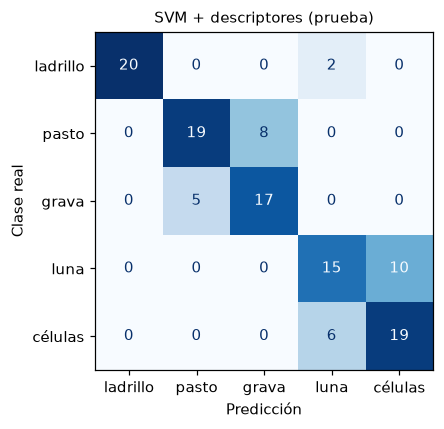

In [6]:
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y[idx_te], pred_clasico, labels=range(len(NOMBRES)), display_labels=NOMBRES, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("SVM + descriptores (prueba)"); ax.set_xlabel("Predicción"); ax.set_ylabel("Clase real")
plt.tight_layout(); plt.show()

## 3. Aprendizaje no supervisado: ¿se agrupan solas las clases?
Si no tuviéramos etiquetas, k-means sobre los descriptores estandarizados nos diría si hay estructura. El **índice de Rand ajustado (ARI)** compara los grupos con las clases reales (1 = coincidencia perfecta, 0 = azar).

In [7]:
Xs = StandardScaler().fit_transform(X_feat)
km = KMeans(len(NOMBRES), n_init=10, random_state=0).fit(Xs)
print("ARI k-means vs clases reales:", round(adjusted_rand_score(y, km.labels_), 3))
display(pd.crosstab(pd.Series([NOMBRES[i] for i in y], name="clase real"), pd.Series(km.labels_, name="cluster")))

ARI k-means vs clases reales: 0.249


cluster,0,1,2,3,4
clase real,,,,,
células,3,2,0,41,54
grava,16,42,42,0,0
ladrillo,58,12,0,29,1
luna,7,7,0,40,46
pasto,16,44,40,0,0


## 4. Red neuronal convolucional desde cero
Una CNN aprende sus propios filtros (¡las mismas convoluciones de la Unidad 2!) a partir de los datos. Empezamos con un ejemplo clásico y rápido: los dígitos manuscritos de 8 × 8 de scikit-learn.

In [8]:
from sklearn.datasets import load_digits
dig = load_digits()
Xd = torch.tensor(dig.images / 16.0, dtype=torch.float32).unsqueeze(1)   # (n, 1, 8, 8)
yd = torch.tensor(dig.target)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25, stratify=yd, random_state=0)

class MiniCNN(nn.Module):
    def __init__(self, n_clases=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),     # 16 filtros 3×3 aprendidos
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                                # 8×8 → 4×4
            nn.Dropout(0.25))
        self.clasificador = nn.Sequential(nn.Flatten(), nn.Linear(32 * 4 * 4, 64), nn.ReLU(), nn.Linear(64, n_clases))
    def forward(self, x):
        return self.clasificador(self.features(x))

modelo = MiniCNN()
print(modelo)
print("Parámetros entrenables:", sum(p.numel() for p in modelo.parameters()))

MiniCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.25, inplace=False)
  )
  (clasificador): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Parámetros entrenables: 38282


Entrenamiento en 5.3s | exactitud final en prueba: 0.982


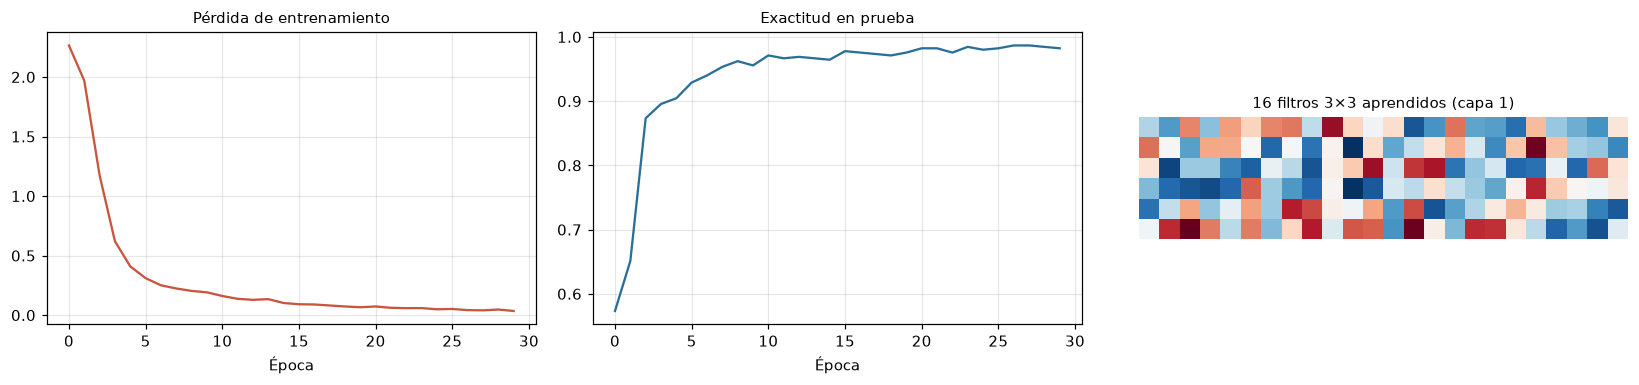

In [9]:
def entrenar(modelo, X_tr, y_tr, X_va, y_va, epocas=30, lr=1e-3, lote=64):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"perdida_tr": [], "exactitud_va": []}
    for ep in range(epocas):
        modelo.train()
        perm = torch.randperm(len(X_tr))
        perdida = 0.0
        for i in range(0, len(X_tr), lote):
            b = perm[i:i + lote]
            opt.zero_grad()
            loss = Fnn.cross_entropy(modelo(X_tr[b]), y_tr[b])
            loss.backward(); opt.step()
            perdida += loss.item() * len(b)
        modelo.eval()
        with torch.no_grad():
            acc = (modelo(X_va).argmax(1) == y_va).float().mean().item()
        hist["perdida_tr"].append(perdida / len(X_tr)); hist["exactitud_va"].append(acc)
    return hist

t0 = time.time()
hist = entrenar(modelo, Xd_tr, yd_tr, Xd_te, yd_te)
print(f"Entrenamiento en {time.time()-t0:.1f}s | exactitud final en prueba: {hist['exactitud_va'][-1]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(hist["perdida_tr"], color="#c8553d"); ax[0].set_title("Pérdida de entrenamiento"); ax[0].set_xlabel("Época")
ax[1].plot(hist["exactitud_va"], color="#2a6f97"); ax[1].set_title("Exactitud en prueba"); ax[1].set_xlabel("Época")
for a in ax[:2]: a.grid(alpha=.3)
filtros = modelo.features[0].weight.detach().squeeze(1)
ax[2].imshow(torch.cat([torch.cat(list(filtros[r*8:(r+1)*8]), 1) for r in range(2)], 0), cmap="RdBu"); ax[2].axis("off")
ax[2].set_title("16 filtros 3×3 aprendidos (capa 1)")
plt.tight_layout(); plt.show()

## 5. Transferencia de aprendizaje con ResNet-18
Entrenar una CNN grande desde cero exige muchísimos datos. La **transferencia de aprendizaje** reutiliza una red preentrenada en ImageNet (1.2 millones de imágenes, 1000 clases) y adapta solo la parte final a nuestro problema:
1. **Extracción de características (linear probing):** congelamos la red y entrenamos un clasificador sobre sus *embeddings* de 512 dimensiones.
2. **Ajuste fino (fine-tuning):** además, reentrenamos las últimas capas con una tasa de aprendizaje pequeña.

In [10]:
pesos = models.ResNet18_Weights.IMAGENET1K_V1
resnet = models.resnet18(weights=pesos).to(DEVICE).eval()
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

normalizar = transforms.Normalize(MEDIA, DESV)

def a_tensor(lote_uint8, tam=96, norm=True):
    """Parches en gris (n, H, W) → tensores RGB en [0, 1] (y normalizados, como espera ResNet)."""
    x = torch.tensor(lote_uint8, dtype=torch.float32).unsqueeze(1).repeat(1, 3, 1, 1) / 255.0
    x = Fnn.interpolate(x, size=(tam, tam), mode="bilinear", align_corners=False)
    return normalizar(x) if norm else x

extractor = nn.Sequential(*list(resnet.children())[:-1])     # todo excepto la capa final (fc)
with torch.no_grad():
    t0 = time.time()
    emb = torch.cat([extractor(a_tensor(X_img[i:i+64]).to(DEVICE)).flatten(1).cpu() for i in range(0, len(X_img), 64)]).numpy()
print(f"Embeddings: {emb.shape} en {time.time()-t0:.1f}s")

probe = Pipeline([("escala", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, C=0.5))])
probe.fit(emb[idx_tr], y[idx_tr])
pred_probe = probe.predict(emb[idx_te])
print("Linear probing (ResNet-18 congelada) → F1 macro en prueba:", round(f1_score(y[idx_te], pred_probe, average="macro"), 3))

Embeddings: (500, 512) en 4.0s


Linear probing (ResNet-18 congelada) → F1 macro en prueba: 0.863


In [11]:
# Ajuste fino: reemplazamos la capa final y entrenamos layer4 + fc con aumento de datos
ft = models.resnet18(weights=pesos)
for nombre_, p in ft.named_parameters():
    p.requires_grad = nombre_.startswith(("layer4", "fc"))
ft.fc = nn.Linear(ft.fc.in_features, len(NOMBRES))
ft = ft.to(DEVICE)

aumento = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
                              transforms.RandomRotation(20), transforms.ColorJitter(0.3, 0.3)])
# El aumento se aplica sobre la imagen en [0, 1] y DESPUÉS se normaliza
Xtr_t, ytr_t = a_tensor(X_img[idx_tr], norm=False), torch.tensor(y[idx_tr])
Xte_t, yte_t = a_tensor(X_img[idx_te]), torch.tensor(y[idx_te])
opt = torch.optim.Adam([p for p in ft.parameters() if p.requires_grad], lr=1e-4)   # tasa pequeña: no "olvidar" lo preentrenado
EPOCAS = 5 if DEVICE == "cpu" else 10
hist_ft = []
t0 = time.time()
for ep in range(EPOCAS):
    ft.train()
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(perm), 32):
        b = perm[i:i + 32]
        xb = normalizar(torch.stack([aumento(x) for x in Xtr_t[b]])).to(DEVICE)
        opt.zero_grad(); loss = Fnn.cross_entropy(ft(xb), ytr_t[b].to(DEVICE)); loss.backward(); opt.step()
    ft.eval()
    with torch.no_grad():
        pred_ft = torch.cat([ft(Xte_t[i:i+64].to(DEVICE)).argmax(1).cpu() for i in range(0, len(Xte_t), 64)]).numpy()
    hist_ft.append(f1_score(y[idx_te], pred_ft, average="macro"))
    print(f"Época {ep+1}: pérdida {loss.item():.3f} | F1 prueba {hist_ft[-1]:.3f}")
print(f"Ajuste fino en {time.time()-t0:.0f}s ({DEVICE})")

Época 1: pérdida 0.847 | F1 prueba 0.527


Época 2: pérdida 0.525 | F1 prueba 0.713


Época 3: pérdida 0.398 | F1 prueba 0.730


Época 4: pérdida 0.582 | F1 prueba 0.754


Época 5: pérdida 0.301 | F1 prueba 0.800
Ajuste fino en 29s (cpu)


## 6. Comparación final en el mismo conjunto de prueba

,Enfoque,Exactitud,F1 macro,Dimensión de la representación
0,"SVM + descriptores (GLCM, LBP)",0.744,0.750,20
1,ResNet-18 congelada + regresión logística,0.860,0.863,512
2,ResNet-18 con ajuste fino,0.802,0.800,512


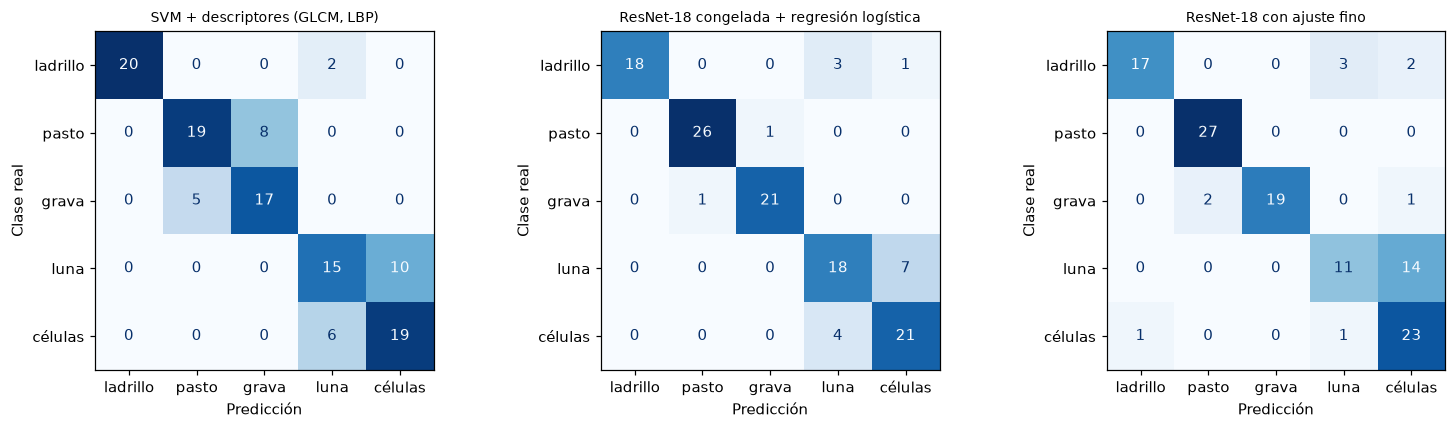

In [12]:
comparacion = pd.DataFrame({
    "Enfoque": ["SVM + descriptores (GLCM, LBP)", "ResNet-18 congelada + regresión logística", "ResNet-18 con ajuste fino"],
    "Exactitud": [accuracy_score(y[idx_te], p) for p in (pred_clasico, pred_probe, pred_ft)],
    "F1 macro": [f1_score(y[idx_te], p, average="macro") for p in (pred_clasico, pred_probe, pred_ft)],
    "Dimensión de la representación": [X_feat.shape[1], emb.shape[1], emb.shape[1]],
}).round(3)
display(comparacion)

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, p, t in zip(axs, (pred_clasico, pred_probe, pred_ft), comparacion["Enfoque"]):
    ConfusionMatrixDisplay.from_predictions(y[idx_te], p, labels=range(len(NOMBRES)), display_labels=NOMBRES, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(t, fontsize=9); ax.set_xlabel("Predicción"); ax.set_ylabel("Clase real")
plt.tight_layout(); plt.show()

**Lectura de resultados.** Los *embeddings* de ResNet-18 superan a los descriptores diseñados a mano aun sin reentrenar la red. El ajuste fino necesita más épocas (y GPU) para superar al *linear probing*: con pocos datos, congelar la red suele ser el punto de partida más seguro. 🧪 *En Colab con GPU, sube `EPOCAS` a 15 y compara.*

💬 **Discusión.** Además del desempeño, considera: tiempo de entrenamiento, cantidad de datos, necesidad de GPU, facilidad para explicar el modelo y costo de mantenimiento. ¿Cuál elegirías para una PyME con 300 imágenes y sin GPU?

## 7. Explicabilidad con Grad-CAM
¿En qué se fija la red para decidir? **Grad-CAM** (Selvaraju et al., 2017) pondera los mapas de activación de la última capa convolucional por el gradiente de la clase predicha. Lo aplicamos a la ResNet-18 original de ImageNet.

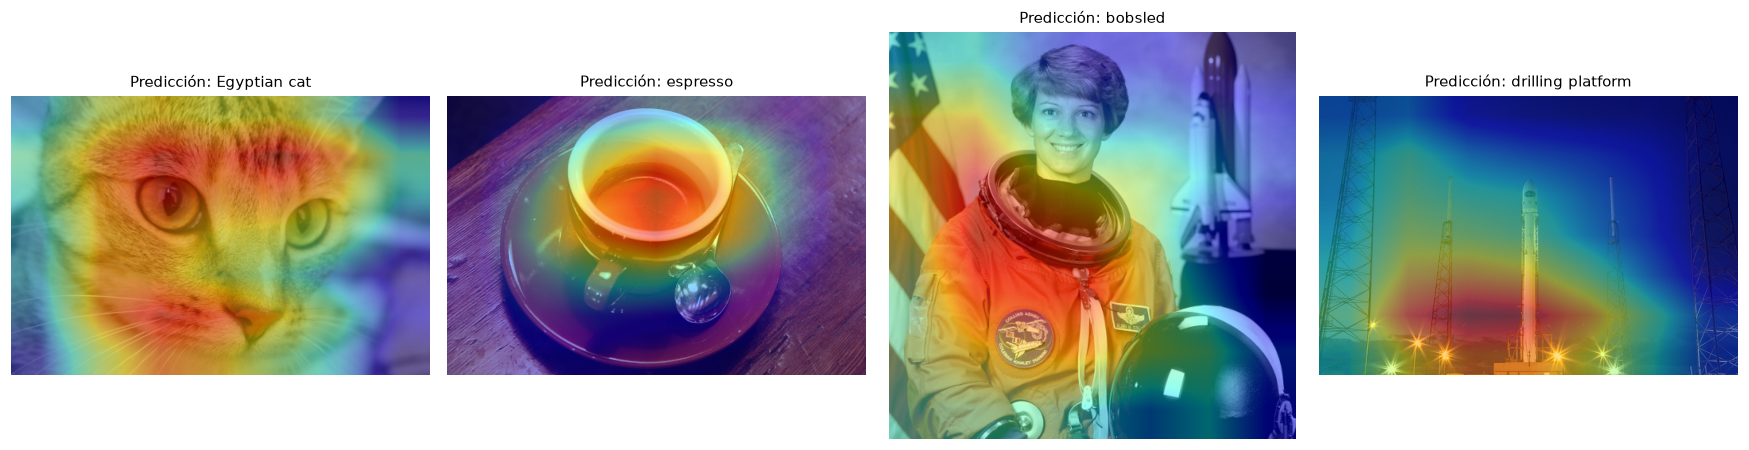

In [13]:
class GradCAM:
    def __init__(self, modelo, capa):
        self.modelo, self.act, self.grad = modelo, None, None
        capa.register_forward_hook(lambda m, i, o: setattr(self, "act", o))
        capa.register_full_backward_hook(lambda m, gi, go: setattr(self, "grad", go[0]))
    def __call__(self, x, clase=None):
        self.modelo.zero_grad()
        salida = self.modelo(x)
        clase = salida.argmax(1).item() if clase is None else clase
        salida[0, clase].backward()
        w = self.grad.mean(dim=(2, 3), keepdim=True)                       # importancia de cada canal
        cam = Fnn.relu((w * self.act).sum(1)).squeeze().detach().cpu().numpy()
        return cam / (cam.max() + 1e-8), clase

modelo_in = models.resnet18(weights=pesos).to(DEVICE).eval()
gc = GradCAM(modelo_in, modelo_in.layer4)
# Redimensionamos la imagen completa (sin recorte central) para que el mapa quede alineado con ella
prep = transforms.Compose([transforms.ConvertImageDtype(torch.float32), transforms.Resize((224, 224), antialias=True),
                           transforms.Normalize(MEDIA, DESV)])
categorias = pesos.meta["categories"]

ejemplos = {"Gato": data.chelsea(), "Café": data.coffee(), "Astronauta": data.astronaut(), "Cohete": data.rocket()}
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (k, im) in zip(axs, ejemplos.items()):
    x = prep(torch.tensor(im).permute(2, 0, 1)).unsqueeze(0).to(DEVICE)
    cam, c = gc(x)
    cam = cv2.resize(cam, (im.shape[1], im.shape[0]))
    ax.imshow(im); ax.imshow(cam, cmap="jet", alpha=0.45); ax.axis("off")
    ax.set_title(f"Predicción: {categorias[c]}")
plt.tight_layout(); plt.show()

💬 **Lee los errores, no solo los aciertos.** ImageNet no tiene clases como «astronauta» o «cohete espacial», así que la red elige la clase más parecida de su vocabulario y Grad-CAM muestra en qué región se apoyó. Esto ilustra dos lecciones para tu proyecto: (1) un modelo preentrenado solo conoce las categorías con las que fue entrenado, por eso lo adaptamos con transferencia de aprendizaje; (2) Grad-CAM permite detectar **atajos** (por ejemplo, que el modelo mire el fondo, una marca de agua o la regla de medición en lugar del objeto).

## 8. Resumen y conexión con la actividad 5A
| Decisión | Buena práctica |
|---|---|
| Partición | Por **grupos** cuando haya imágenes correlacionadas (lote, paciente, escena) |
| Preprocesamiento | Dentro de un `Pipeline` para no filtrar información de prueba |
| Métrica | F1 macro y matriz de confusión; nunca solo exactitud con clases desbalanceadas |
| Modelo | Empieza simple (descriptores + SVM); compara con transferencia de aprendizaje |
| Confianza | Revisa errores y Grad-CAM: ¿el modelo mira lo correcto? |

**Actividad 5A. Flujo completo de procesamiento y reconocimiento** (30 puntos, entrega: domingo 16 de mayo de 2027). Construye tu flujo completo con la plantilla `5A_Plantilla_Flujo_completo.ipynb`. La comparación con transferencia de aprendizaje (secciones 4 a 7) es **opcional**: el núcleo de la actividad es el flujo clásico bien evaluado.